# 让计算机与 AI 帮你完成一个材料科研任务

AI Agent 材料科研实践 · 第一课

**从重复劳动，到可检查、可复用的工作流**

今天带走：一份任务说明 + 一次可复现计算。

00–10 分钟。先问：你上周重复做过三次以上的操作是什么？收集两例，不展开工具清单。

# 今天的路线

问题 → 输入 → 执行 → 检查 → 复用

- 先复核：文件、环境、搜索与 Python
- 再理解：模型、工具与 Agent 如何协作
- 一起做：模拟拉伸数据处理
- 自己写：科研任务说明

强调第一课的目标和交付；后续第二讲继续环境/Python，第三讲机器学习，第四讲 API/Agent。

# 先看终点：五行数据变成什么？

| 输入 | 处理 | 输出 |
|---|---|---|
| 位移 mm、力 N | 工程应力 = 力 / 初始面积 | 带单位的 CSV 和图 |

**100 N ÷ 2.0 mm² = 50 MPa**

数据为教学模拟；只展示工作流，不报告真实材料性能。

展示 data/tensile_demo.csv 和已生成输出。先给结果，再追问如何知道它算对了。

# 预习诊断：你能指出它们吗？

1. 你的代码在哪里运行？
2. 数据文件在哪里？当前目录在哪里？
3. 解释器和编辑器分别是什么？
4. 应力的单位为什么是 MPa？
5. 程序报错，你会给同伴什么信息？

10–25 分钟。两人互答；环境个别问题记到问题单，休息时处理。

# 把“不能跑”变成可解决的问题

**含糊**：老师，Python 坏了。

**可复现**：运行哪个命令、在什么目录、用哪个解释器、完整报错是什么、已经尝试了什么。

搜索例：`Python FileNotFoundError relative path pathlib`

先找官方文档，再用最短例子验证。

请一名学生用真实错误改写求助。强调分享与引用来源，AI 回答也需要验证。

# 一次数据处理经过哪里？



[打开交互演示](http://127.0.0.1:8765/slidev/public/lab.html?mode=flow)（需先启动本机演示服务）

25–40 分钟。点击分步动画；追问：关掉内核后什么还在？说明是简化示意，真实系统有缓存和更多层次。

# 硬件不需要背参数

| 部件 | 这次任务中做什么 |
|---|---|
| CPU | 执行程序的计算指令 |
| RAM | 保存正在处理的数据与变量 |
| 磁盘 | 保存 CSV、程序和结果 |
| GPU | 适合大量并行计算，本例不用 |

操作系统管理进程、文件和设备；远程运行时，这些资源可能在另一台机器上。

用实验台与档案柜作辅助比喻，但不展开硬件采购。

# GUI、CLI、TUI：不同的交互方式

| 界面 | 操作方式 | 例子 |
|---|---|---|
| GUI | 窗口、按钮、鼠标 | 文件管理器 |
| CLI | 输入命令 | `python hello.py` |
| TUI | 终端中的文本交互界面 | 终端编辑器 |

**终端承载交互；shell 解析命令；程序完成任务。**

现场用文件管理器与终端定位同一文件。避免把终端、命令行和 TUI 完全等同。

# 写代码与运行代码，是两件事

编辑器 → `.py` 文件 → Python 解释器 → 输出

Notebook 页面 → 内核 → 变量状态 / 输出

- 保存代码，不等于保存内核里的所有变量
- 重启内核并从头运行，检查是否漏了步骤
- CPython 通常先编译为字节码，再执行

40–60 分钟。演示 sys.executable 和 Path.cwd；说明相对路径是相对工作目录。

# 读懂这段程序，已经可以开始

先预测输出；把 25 改成 80；再运行。

In [1]:
def to_kelvin(value):
    return value + 273.15

for temperature in [25, 40, 60]:
    print(to_kelvin(temperature), "K")

298.15 K
313.15 K
333.15 K


讲清列表、变量、函数和循环。无需先教授所有语法。

# 真正动手：改参数，再运行



[打开交互演示](http://127.0.0.1:8765/slidev/public/lab.html?mode=code)（需先启动本机演示服务）

In [2]:
def stress(force_n, area_mm2):
    if area_mm2 <= 0:
        raise ValueError("初始截面积必须大于 0")
    return force_n / area_mm2

area = 2.0
for force in [0, 50, 100, 150, 180]:
    print(f"{force} N -> {stress(force, area):.1f} MPa")

0 N -> 0.0 MPa
50 N -> 25.0 MPa
100 N -> 50.0 MPa
150 N -> 75.0 MPa
180 N -> 90.0 MPa


让学生先手算 100/4。点击运行，再试面积为零。运行器是本机 Python，每次独立进程，不是 AI。

# 结构化输入，让自动化有抓手

| 形式 | 适合表达什么 |
|---|---|
| Markdown | 目标、步骤、验收方法 |
| CSV | 字段统一的表格 |
| JSON | 有层级的结构化结果 |

字段名、单位、缺失值约定和来源，比表格配色更影响可复用性。

让学生把“力大约一百，截面是二”改写为 force_n=100、area_mm2=2.0。

# AI 概念放到各自的位置

AI：广泛的研究与应用领域

机器学习：从数据拟合规律 → 神经网络：一类可训练模型

**LLM**：语言与代码；**VLM**：图像与语言，能力可交叠

**Agent**：模型 + 工具 + 执行循环；属于系统层面的组织方式。

60–75 分钟。这里只建立地图，不讲反向传播与 Transformer 公式。

# 把材料任务交给合适的方法

| 科研任务 | 合适起点 | 必须检查 |
|---|---|---|
| 单位换算 | 确定性程序 | 公式、单位 |
| 配方到性能 | 机器学习 | 数据划分、误差 |
| 文献内容整理 | LLM | 原文证据 |
| 谱图/显微图信息 | VLM / 专用方法 | 坐标、标尺、分辨率 |
| 多步文件处理 | Agent + 工具 | 文件、日志、验收 |

不是所有任务都需要大模型。VLM 读懂图意，不保证坐标读数精确。

# Agent 如何把建议变成操作？



[打开交互演示](http://127.0.0.1:8765/slidev/public/lab.html?mode=agent)（需先启动本机演示服务）

逐步说明模型只是提出工具请求，harness 实际执行与返回结果。明确此动画是教学模拟。

# 休息 15 分钟

回来后：一起处理模拟拉伸数据。

**请保留你的报错原文。**

环境未完成的同学集中求助；其他同学写一句自己的重复劳动痛点。

75–90 分钟。严格控制休息和个别排障，主课按时恢复。

# 主任务：把要求写清楚

输入：五行模拟力—位移 CSV；初始面积 2.0 mm²。

步骤：校验 → 计算工程应力 → 画图 → 保存。

输出：stress_mpa 列、单位、数据来源与处理说明。

验收：100 N 对应 50 MPa；面积非正时报错。

**保留原始数据。**

90–115 分钟。打开任务模板。若使用现场 Agent，先给它这份说明，展示真实工具记录；否则用 Notebook 完成相同流程。

# 先预测，再拖动



[打开交互演示](http://127.0.0.1:8765/slidev/public/lab.html?mode=stress)（需先启动本机演示服务）

/root/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-hp2fzxf6 because there was an issue with the default path (/root/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
notebook-cell-3:38: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
100 N -> 50.0 MPa
Saved: outputs/stress.csv


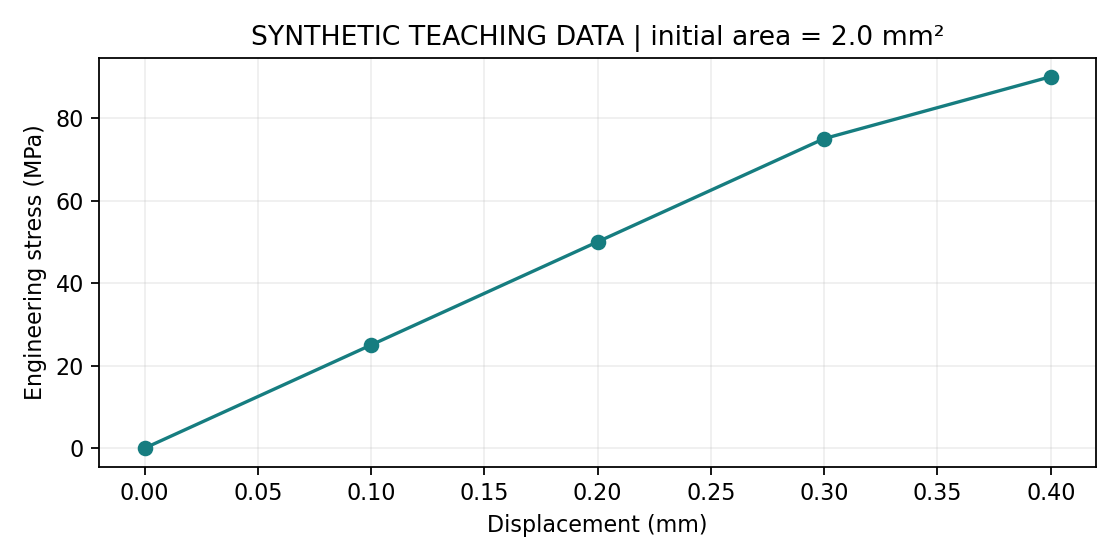

In [3]:
# 改 area_mm2 后重新执行；图像和 CSV 保存到 outputs。
from pathlib import Path
import csv
import math
import matplotlib.pyplot as plt

root = Path.cwd().resolve()
if not (root / 'data/tensile_demo.csv').exists():
    root = root.parent
if not (root / 'data/tensile_demo.csv').exists():
    raise FileNotFoundError('请在 lesson01 或 lesson01/notebook 目录运行')
area_mm2 = 2.0
if not math.isfinite(area_mm2) or area_mm2 <= 0:
    raise ValueError('初始截面积必须是有限正数')
with (root / 'data/tensile_demo.csv').open(newline='', encoding='utf-8') as f:
    rows = list(csv.DictReader(f))
if not rows:
    raise ValueError('输入为空')
for row in rows:
    force = float(row['force_n'])
    displacement = float(row['displacement_mm'])
    if not math.isfinite(force) or not math.isfinite(displacement):
        raise ValueError('力与位移必须是有限数')
    row['stress_mpa'] = force / area_mm2
out = root / 'outputs'
out.mkdir(exist_ok=True)
with (out / 'stress.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
assert abs(float(rows[2]['stress_mpa']) - 100 / area_mm2) < 1e-9
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([float(r['displacement_mm']) for r in rows], [r['stress_mpa'] for r in rows], 'o-', color='#167d80')
ax.set(xlabel='Displacement (mm)', ylabel='Engineering stress (MPa)', title=f'SYNTHETIC TEACHING DATA | initial area = {area_mm2} mm²')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(out / 'stress.png', dpi=160)
plt.show()
plt.close(fig)
(out / 'processing.txt').write_text(f'Synthetic teaching data; area_mm2={area_mm2}; stress=force/initial_area; N/mm²=MPa. Not a material property report.', encoding='utf-8')
print('100 N ->', rows[2]['stress_mpa'], 'MPa')
print('Saved:', out / 'stress.csv')

将面积从 2 改到 4，曲线纵轴固定；同一力值的应力减半。强调位移不是应变。

# 检查比“运行成功”更重要

- 数值：100 N / 2 mm² = 50 MPa
- 单位：N/mm² = MPa；cm² 不能直接混用
- 输入：面积必须为正；缺失列应报错
- 证据：输出文件存在，来源与参数有记录
- 重现：从空内核重新运行得到同样结果

现场插入无效面积；让学生解释为何报错比悄悄输出无穷大好。不能仅凭曲线漂亮判断正确。

# 不能从这张图得出什么？

**没有标距，不能把位移直接写成应变。**

没有完整实验与标定，不能报告弹性模量、屈服或断裂强度。

AI 可以帮你生成图与文字；实验假设和材料学解释需要你来判断。

让学生提出一个看起来合理但证据不足的结论，及时纠正。

# 你的任务说明：六个部分

1. 研究目标与重复劳动痛点
2. 输入文件、来源、字段、单位
3. 可执行的处理步骤
4. 期望输出与保存方式
5. 手算样例与异常检查
6. 边界、假设与 AI 使用记录

115–130 分钟。展示 task_template.md，让同桌只读说明就能复述任务。

# 开放共享，让下一次更容易

找到答案 → 验证答案 → 记录来源 → 分享最小例子

把一次排错沉淀成别人能复用的说明。

**把勤奋用在问题与验证，把重复交给程序。**

联系 SI100+ 和开源工具贡献者。讨论“懒得再手动整理一次”如何转化成自动化需求。

# 时间也要算进成本

示例假设：手动 10 分钟/次。

自动化：首次整理 40 分钟，之后每次运行与核验 2 分钟。

累计 5 次约打平；更多重复才逐步省时。

工具费用、维护、失败重试也要算；付费 token 是可选投资。

请学生解释 10n=40+2n；不提供供应商价格。小样本先试、给自动任务设预算和停止条件。

# 35 分钟：把任务变成自己的

**基础组**：运行 → 改面积 → 手算检查 → 写 task.md。

**进阶组**：增加缺失列/无效值检查，记录失败行为。

10 分钟运行 / 15 分钟修改与写作 / 10 分钟互查。

提交：任务说明、输入、输出、检查记录。

130–165 分钟。没有真实数据用教学 CSV；结对也要轮流操作，各交一份自己的任务说明。

# 互查：同伴能复现吗？

- 输入找得到吗？字段与单位明确吗？
- 步骤能执行吗？输出有定义吗？
- 是否有手算核对和异常检查？
- 从头运行能否得到相同结果？

展示两组：请指出一个尚未验证的假设。

165–175 分钟。用大纲六项量规形成性反馈，避免只展示成功截图。

# 离堂前，回答三问

**我的代码在哪里运行？**

**哪个结果是我亲自检查过的？**

**下次重复这个任务，需要保留哪些文件？**

课后完善 task.md 与样例；第二讲继续 Python / Jupyter 与环境工具。

175–180 分钟。收集离堂卡，安排未达标同学下一讲前补习。

# 资料与致谢

- SI100+：计算机基础、搜索、Python 入门
- Python、Jupyter、Slidev 与开源社区
- 详细来源见 `00_资料核对与来源.md`

本课数据与演示流程为教学构造。

课件里的 Agent 流程动画不是实际模型运行记录。

补充页，不占额外讲授时间。视频 2026 与本地 2024 讲义分开标注。